<a href="https://colab.research.google.com/github/pyKi11er/deep_net_dev/blob/main/dnd26autumn_practice_week6_worksheet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Network Development, 2026 Autumn - Week 6 Practice - **Exercise sheet**

## Exercises

---

### Exercise 6.1: Exploring penguin measurements

#### Problem Description

The [Palmer Penguins dataset](https://allisonhorst.github.io/palmerpenguins/)
contains measurements of individual penguins. Species is a multi-class
classification target, body mass is a regression target.

Download and explore the original CSV. Keep species, the four measurements, and sex, but
skip island and year. Keep NaNs and outliers in the
dataset, selecting temporary subsets only when needed for plotting.


In [1]:
import urllib.request
import numpy as np
import matplotlib.pyplot as plt

DATA_URL = (
    'https://raw.githubusercontent.com/allisonhorst/palmerpenguins/'
    '156daa4301838d9fdcc5b018b29b9149bf975552/inst/extdata/penguins.csv'
)

species_dict = {'Adelie': 0, 'Chinstrap': 1, 'Gentoo': 2}
sex_dict = {'female': 0, 'male': 1}
SPECIES_NAMES = np.array(['Adelie', 'Chinstrap', 'Gentoo'])
COLUMN_NAMES = np.array(['species', 'bill_length_mm', 'bill_depth_mm',
                         'flipper_length_mm', 'body_mass_g', 'sex'])


#### Task 1: Naive CSV loading and labels

Download `DATA_URL` as UTF-8 text. Split it into lines and comma-separated fields,
skip the header, and store the records in the nested list of strings `data`.

Use nested loops to create the numeric nested list `dataset`. For each field,
strip whitespace and choose its conversion using its original CSV column index:

- Column 0 (species): use `species_dict`.
- Columns 2-5 (measurements): convert `'NA'` to `np.nan`, otherwise use `float()`.
- Column 6 (sex): convert `'NA'` to `np.nan`, otherwise use `sex_dict`.
- Skip columns 1 and 7 (island and year).

Convert `dataset` to `dataset_arr` with `np.float32` dtype. Extract column 0 into
the 1D integer array `labels_class`, and column 4 into the floating-point array
`targets_reg`. Print their shapes and dtypes.


In [6]:
with urllib.request.urlopen(DATA_URL, timeout=30) as stream:
    content = stream.read().decode('utf-8')
lines = content.splitlines()
data = [line.split(',') for line in lines[1:]]

# Implement your solution below

dataset = []
for rec in data:
  dataset_row = []
  for item_idx, item in enumerate(rec):
    item = item.strip()
    if item_idx == 0:
      val = species_dict[item]
    elif item_idx in {2,3,4,5}:
      val = np.nan if item == 'NA' else float(item)
    elif item_idx == 6:
      val = np.nan if item == 'NA' else sex_dict[item]
    else:
      continue
    dataset_row.append(val)
  dataset.append(dataset_row)

dataset_arr = np.array(dataset, dtype = np.float32)
labels_class = dataset_arr[:, 0].astype(np.int64)
targets_reg = dataset_arr[:, 4]





# Prints
print('Dataset:', dataset_arr.shape, dataset_arr.dtype)
print('Classification labels:', labels_class.shape, labels_class.dtype)
print('Regression targets:', targets_reg.shape, targets_reg.dtype)

# Test cases
assert dataset_arr.shape == (344, 6) and dataset_arr.dtype == np.float32
assert np.allclose(dataset_arr[0], [0, 39.1, 18.7, 181, 3750, 1])
assert np.isnan(dataset_arr[3, 1:]).all()
assert labels_class.shape == targets_reg.shape == (344,)
assert np.issubdtype(labels_class.dtype, np.integer)
assert np.issubdtype(targets_reg.dtype, np.floating)
assert np.array_equal(labels_class[:3], [0, 0, 0])
assert labels_class[152] == 2 and labels_class[276] == 1
assert np.isnan(targets_reg[3])
assert np.allclose(targets_reg[:3], [3750, 3800, 3250])
assert dataset_arr[1, 5] == 0 and np.isnan(dataset_arr[8, 5])
print('Task 1 passed!')


Dataset: (344, 6) float32
Classification labels: (344,) int64
Regression targets: (344,) float32
Task 1 passed!


#### Provided setup

Run this after Task 1. It adds a few artificial measurement errors and selects
the sex field for plotting. Both targets and all missing values remain unchanged.


In [7]:
# Add a few measurement errors
dataset_arr[7, 1] = 392
dataset_arr[83, 2] = 194
dataset_arr[176, 1:3] = [500, 200]
dataset_arr[270, 1] = -440
dataset_arr[320, 2] = 150

measurements = dataset_arr[:, 1:5]
MEASUREMENT_NAMES = COLUMN_NAMES[1:5]
BILL_LENGTH, BILL_DEPTH, FLIPPER_LENGTH, BODY_MASS = range(4)
sex = dataset_arr[:, 5]  # female: 0, male: 1, unknown: NaN


#### Task 2: Exploring missing values

Create the boolean `missing_mask` for `dataset_arr`. Compute and print:

- `n_missing`: total number of missing cells.
- `missing_per_column`: count for each column, shape `(6,)`.
- `n_rows_with_missing`: number of penguins with at least one missing field.

Also print the names of the columns with missing values, using `missing_per_column`.


In [10]:
# Implement your solution below




missing_mask = np.isnan(dataset_arr)
n_missing = np.count_nonzero(missing_mask)
missing_per_column = np.sum(missing_mask, axis = 0)
n_rows_with_missing = np.sum(np.any(missing_mask, axis = 1))


# Prints
print('Missing cells:', n_missing)
print('Missing per column:', missing_per_column)
print('Affected columns:', COLUMN_NAMES[missing_per_column > 0])
print('Affected rows:', n_rows_with_missing)

# Test cases
assert missing_mask.shape == (344, 6) and missing_mask.dtype == np.bool_
assert n_missing == 19 and n_rows_with_missing == 11
assert np.array_equal(missing_per_column, [0, 2, 2, 2, 2, 11])
print('Task 2 passed!')


Missing cells: 19
Missing per column: [ 0  2  2  2  2 11]
Affected columns: ['bill_length_mm' 'bill_depth_mm' 'flipper_length_mm' 'body_mass_g' 'sex']
Affected rows: 11
Task 2 passed!


#### Task 3: NaN-aware column statistics


For `measurements`, compute `column_means`, `column_medians`, `column_vars`, and
`column_stds`: arrays of shape `(4,)`, ignoring missing values independently in
each column. Print the column names and results.


In [15]:
# Implement your solution below

# np.mean(measurements[~np.isnan(measurements)], axis = 0)

column_means = np.nanmean(measurements, axis = 0)
column_medians = np.nanmedian(measurements, axis = 0)
column_vars = np.nanvar(measurements, axis = 0)
column_stds = np.nanstd(measurements, axis = 0)


# Prints
print('Columns:', MEASUREMENT_NAMES)
print('Means:', column_means)
print('Medians:', column_medians)
print('Variances:', column_vars)
print('Standard deviations:', column_stds)

# Test cases

assert all(arr.shape == (4,) for arr in
           [column_means, column_medians, column_vars, column_stds])
assert np.allclose(column_means, [44.865517, 18.594444, 200.915205, 4201.754386], atol=0.01)
assert np.allclose(column_medians, [44.5, 17.3, 197, 4050], atol=0.01)
assert np.allclose(column_vars, [1675.9408, 242.553858, 197.153628, 641250.577], rtol=1e-4)
assert np.allclose(column_stds, [40.938255, 15.574141, 14.041141, 800.781229], rtol=1e-4)
print('Task 3 passed!')


Columns: ['bill_length_mm' 'bill_depth_mm' 'flipper_length_mm' 'body_mass_g']
Means: [  44.865517   18.594444  200.9152   4201.7544  ]
Medians: [  44.5   17.3  197.  4050. ]
Variances: [1.6759408e+03 2.4255377e+02 1.9715363e+02 6.4125081e+05]
Standard deviations: [ 40.938255  15.574138  14.041141 800.7814  ]
Task 3 passed!


#### Task 4: Finding and counting outliers


Flag a measurement when $|x_{ij}-\mu_j| > 3\sigma_j$, using the statistics from
Task 3. All four standard deviations are nonzero. A NaN must not be flagged.

Create:

- `outlier_mask`: boolean array of shape `(344, 4)`.
- `outlier_counts_per_column`: flagged-cell counts, shape `(4,)`.
- `outlier_row_indices`: 0-based indices of penguins with any flagged measurement.
- `n_outlier_cells` and `n_outlier_rows`: the two totals.


In [21]:
# Implement your solution below

outlier_mask = np.abs(measurements - column_means) > 3 * column_stds
outlier_counts_per_column = np.count_nonzero(outlier_mask, axis = 0)
outlier_row_indices = np.where(np.any(outlier_mask, axis = 1))[0]
n_outlier_cells = np.count_nonzero(outlier_mask)
n_outlier_rows = np.count_nonzero(np.any(outlier_mask, axis = 1))


# Prints
print('Counts per measurement:', outlier_counts_per_column)
print('Flagged cells / rows:', n_outlier_cells, n_outlier_rows)
print('Flagged row indices:', outlier_row_indices)
print(measurements[outlier_row_indices])

# Test cases

assert outlier_mask.shape == (344, 4) and outlier_mask.dtype == np.bool_
assert not np.any(outlier_mask[np.isnan(measurements)])
assert np.array_equal(outlier_counts_per_column, [3, 3, 0, 0])
assert np.array_equal(outlier_row_indices, [7, 83, 176, 270, 320])
assert n_outlier_cells == 6 and n_outlier_rows == 5
print('Task 4 passed!')


Counts per measurement: [3 3 0 0]
Flagged cells / rows: 6 5
Flagged row indices: [  7  83 176 270 320]
[[ 392.    19.6  195.  4675. ]
 [  35.1  194.   193.  4200. ]
 [ 500.   200.   215.  5000. ]
 [-440.    13.7  214.  4925. ]
 [  50.9  150.   196.  3675. ]]
Task 4 passed!


#### Task 5: Species distribution and a bar chart


Compute the species distribution in two ways:

- `species_values`, `species_counts`: using `np.unique(..., return_counts=True)`.
- `species_counts_bincount`: using `np.bincount(..., minlength=3)`.

Plot the counts as a bar chart, with species names on the horizontal axis.
Add axis labels and a title.


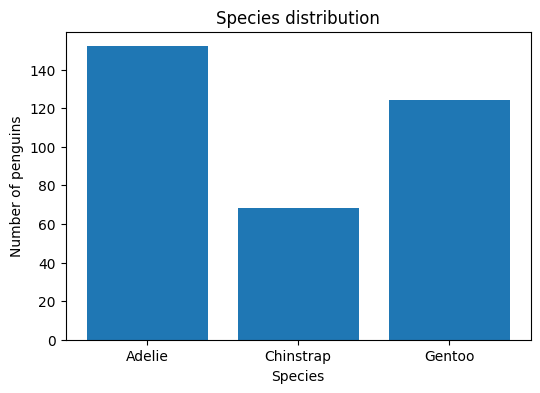

Task 5 passed!


In [32]:
fig, ax = plt.subplots(figsize=(6, 4))
# Implement your solution below

species_values, species_counts = np.unique(labels_class, return_counts = True)

species_counts_bincount = np.bincount(labels_class, minlength = 3)


ax.bar(species_values, species_counts)
ax.set_xticks(species_values, SPECIES_NAMES[species_values])
ax.set_xlabel('Species')
ax.set_ylabel('Number of penguins')
ax.set_title('Species distribution')
plt.show()

# Test cases

assert np.array_equal(species_values, [0, 1, 2])
assert np.array_equal(species_counts, [152, 68, 124])
assert np.array_equal(species_counts_bincount, species_counts)
assert species_counts.sum() == 344
print('Task 5 passed!')


#### Task 6: Body-mass histograms for two groups


Create `female_mass` and `male_mass`: 1D arrays of known body masses for penguins
whose recorded sex is female or male, respectively. Exclude missing body masses
and missing sex only from this calculation. Do not change `dataset_arr`.

Use the shared `mass_edges` below to compute `female_hist` and `male_hist` with
`np.histogram`. Plot the two groups with `axes[0].hist` and `axes[1].hist`, using
those same edges. Add titles and axis labels.


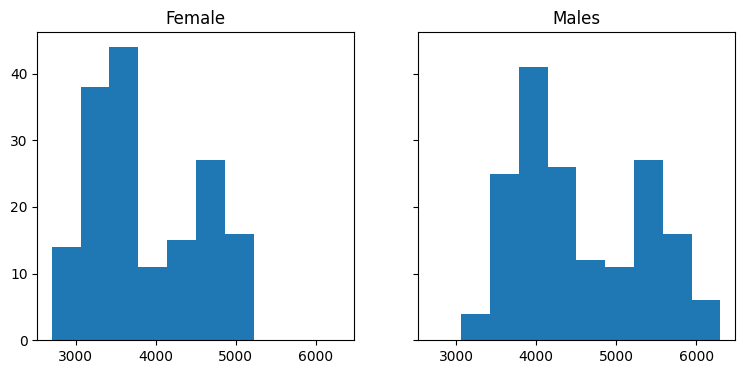

Task 6 passed!


In [37]:
mass_edges = np.linspace(np.nanmin(targets_reg), np.nanmax(targets_reg), 11)
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(9, 4))
# Implement your solution below

valid_mass = ~np.isnan(targets_reg)
female_mass = targets_reg[valid_mass & (sex == 0)]
male_mass = targets_reg[valid_mass & (sex == 1)]

female_hist, _ = np.histogram(female_mass, bins = mass_edges)
male_hist, _ = np.histogram(male_mass, bins = mass_edges)

axes[0].hist(female_mass, bins = mass_edges)
axes[0].set_title('Female')
axes[1].hist(male_mass, bins = mass_edges)
axes[1].set_title('Males')
plt.show()





# Test cases

assert female_mass.shape == (165,) and male_mass.shape == (168,)
assert np.isfinite(female_mass).all() and np.isfinite(male_mass).all()
assert female_hist.shape == male_hist.shape == (10,)
assert np.array_equal(female_hist, [14, 38, 44, 11, 15, 27, 16, 0, 0, 0])
assert np.array_equal(male_hist, [0, 4, 25, 41, 26, 12, 11, 27, 16, 6])
print('Task 6 passed!')


#### Task 7: A 2D histogram with pcolormesh


Create `valid_pair_mask` selecting penguins with both a known flipper length and
a known body mass. Use these pairs to compute `hist2d`, `flipper_edges`, and
`body_mass_edges` with `np.histogram2d`, using **12 flipper bins and 8 body-mass bins**.

Plot the counts with `ax.pcolormesh`: flipper length on the horizontal axis and
body mass on the vertical axis. Store the returned object in `mesh`, add a
colorbar, a title, and axis labels with units.

**Hint:** `histogram2d` indexes counts as `[x_bin, y_bin]`, while `pcolormesh`
expects `[y_bin, x_bin]`.


Task 7 passed!


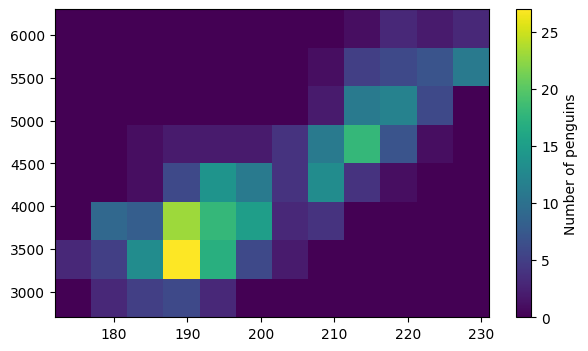

In [44]:
fig, ax = plt.subplots(figsize=(7, 4))
# Implement your solution below

flipper = measurements[:, FLIPPER_LENGTH]
valid_pair_mask = ~np.isnan(flipper) & ~np.isnan(targets_reg)
hist2d, flipper_edges, body_mass_edges = np.histogram2d(flipper[valid_pair_mask], targets_reg[valid_pair_mask], bins = (12,8))

mesh = ax.pcolormesh(flipper_edges, body_mass_edges, hist2d.T)
fig.colorbar(mesh, ax=ax, label='Number of penguins')

plt.show()

# Test cases

assert valid_pair_mask.shape == (344,) and valid_pair_mask.dtype == np.bool_
assert np.count_nonzero(valid_pair_mask) == 342
assert hist2d.shape == (12, 8) and hist2d.sum() == 342
assert flipper_edges.shape == (13,) and body_mass_edges.shape == (9,)
assert np.allclose(flipper_edges[[0, -1]], [172, 231])
assert np.allclose(body_mass_edges[[0, -1]], [2700, 6300])
assert hist2d[0, 1] == 3 and hist2d[-1, -1] == 3
print('Task 7 passed!')


#### Task 8: Conditional species distributions

Using the recorded sex, compute `female_species_counts` and `male_species_counts`:
arrays of shape `(3,)`, containing the number of penguins of each species in
the order given by `SPECIES_NAMES`. Exclude unknown sex, but do not filter on
body mass or remove outlier rows.

Plot the two distributions as bar charts on subplots with a shared y-axis.
Use species names for tick labels and add titles and axis labels.


In [ ]:
fig8, axes8 = plt.subplots(1, 2, sharey=True, figsize=(9, 4))

# Implement your solution below






# Test cases
assert female_species_counts.shape == male_species_counts.shape == (3,)
assert np.array_equal(female_species_counts, [73, 34, 58])
assert np.array_equal(male_species_counts, [73, 34, 61])
assert female_species_counts.sum() + male_species_counts.sum() == 333
assert np.all(female_species_counts + male_species_counts <= species_counts)
print('Task 8 passed!')


#### Task 9: Scatter plot colored by species

Plot flipper length (horizontal axis) against body mass (vertical axis), using a
different color and legend entry for each species. Reuse `valid_pair_mask` from
Task 7 to select observations with both measurements known.

Compute `scatter_counts_per_species`, a `(3,)` array giving the number of plotted
penguins of each species. Add a title, a legend, and axis labels with units.


In [ ]:
fig9, ax9 = plt.subplots(figsize=(7, 4))

# Implement your solution below






# Test cases
assert scatter_counts_per_species.shape == (3,)
assert np.array_equal(scatter_counts_per_species, [151, 68, 123])
assert scatter_counts_per_species.sum() == np.count_nonzero(valid_pair_mask) == 342
print('Task 9 passed!')


#### Task 10: Body-mass statistics by species

Compute `species_mass_means`, `species_mass_medians`, and `species_mass_stds`:
three arrays of shape `(3,)`, in the order given by `SPECIES_NAMES`.
Use each species' body masses, ignore NaNs, and use population standard deviation. Print the results alongside the species names.


In [ ]:
# Implement your solution below






# Test cases
assert species_mass_means.shape == species_mass_medians.shape == species_mass_stds.shape == (3,)
assert np.allclose(species_mass_means, [3700.662252, 3733.088235, 5076.016260], atol=0.01)
assert np.allclose(species_mass_medians, [3700, 3700, 5000], atol=0.01)
assert np.allclose(species_mass_stds, [457.045173, 381.498621, 502.062801], atol=0.01)
assert np.all(species_mass_stds < column_stds[BODY_MASS])
print('Task 10 passed!')
